#**Cargar librerías**
Lo primero que debemos hacer es cargar las librerías necesarias para la manipulación de nuestro conjunto de datos


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#**Cargar conjunto de datos**
Aquí debemos seleccionar el(los) conjunto(s) de datos.

In [2]:
# Debemos elegir un nombre para nuestro conjunto de datos y usar el comando "pd.read_csv" para cargarlo.
df = pd.read_csv('Obesity Classification.csv', encoding='latin-1', index_col='ID')
df

,Age,Gender,Height,Weight,BMI,Label
ID,,,,,,
1,25,Male,175,80,25.3,Normal Weight
2,30,Female,160,60,22.5,Normal Weight
3,35,Male,180,90,27.3,Overweight
4,40,Female,150,50,20.0,Underweight
5,45,Male,190,100,31.2,Obese
...,...,...,...,...,...,...
106,11,Male,175,10,3.9,Underweight
107,16,Female,160,10,3.9,Underweight
108,21,Male,180,15,5.6,Underweight


##Análisis rápido del conjunto de datos

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 108 entries, 1 to 110
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Age     108 non-null    int64  
 1   Gender  108 non-null    object 
 2   Height  108 non-null    int64  
 3   Weight  108 non-null    int64  
 4   BMI     108 non-null    float64
 5   Label   108 non-null    object 
dtypes: float64(1), int64(3), object(2)
memory usage: 5.9+ KB


#**Tablas de frecuencia**

Creamos una tabla de frecuencias para la columna *Label*.

In [4]:
tab = pd.crosstab(index=df['Label'],columns="frecuencia")
tab

col_0,frecuencia
Label,
Normal Weight,29
Obese,12
Overweight,20
Underweight,47


In [5]:
tab =tab.reset_index()
tab

col_0,Label,frecuencia
0,Normal Weight,29
1,Obese,12
2,Overweight,20
3,Underweight,47


## Frecuencia relativa

Agregamos la columna de frecuencia relativa.

In [6]:
#shape nos dice el tamaño, si usamos [0] nos da el número de renglones
#si usamos [1] nos da el número de columnas
df.shape[0]

108

In [7]:
tab['frec_relativa'] = tab['frecuencia']/df.shape[0]
tab

col_0,Label,frecuencia,frec_relativa
0,Normal Weight,29,0.268519
1,Obese,12,0.111111
2,Overweight,20,0.185185
3,Underweight,47,0.435185


In [8]:
#round redondea al número de decimales indicado
tab['frec_relativa'] = round(tab['frecuencia']/df.shape[0],3)
tab

col_0,Label,frecuencia,frec_relativa
0,Normal Weight,29,0.269
1,Obese,12,0.111
2,Overweight,20,0.185
3,Underweight,47,0.435


Agregamos la columna de frecuencia porcentaje.

In [9]:
tab['porcentaje'] = round(tab['frec_relativa']*100,2)
tab

col_0,Label,frecuencia,frec_relativa,porcentaje
0,Normal Weight,29,0.269,26.9
1,Obese,12,0.111,11.1
2,Overweight,20,0.185,18.5
3,Underweight,47,0.435,43.5


## Frecuencia acumulada

In [10]:
#cumsum devuelve la suma acumulada sobre un eje DataFrame o Series.
tab['frec_acumulada'] = round(tab['frec_relativa'],3).cumsum()
tab

col_0,Label,frecuencia,frec_relativa,porcentaje,frec_acumulada
0,Normal Weight,29,0.269,26.9,0.269
1,Obese,12,0.111,11.1,0.380
2,Overweight,20,0.185,18.5,0.565
3,Underweight,47,0.435,43.5,1.000


#**Histogramas**

In [11]:
#El comando "unique" nos sirve para conocer los diferentes valores que hay en cada columna
df.Label.unique()

array(['Normal Weight', 'Overweight', 'Underweight', 'Obese'],
      dtype=object)

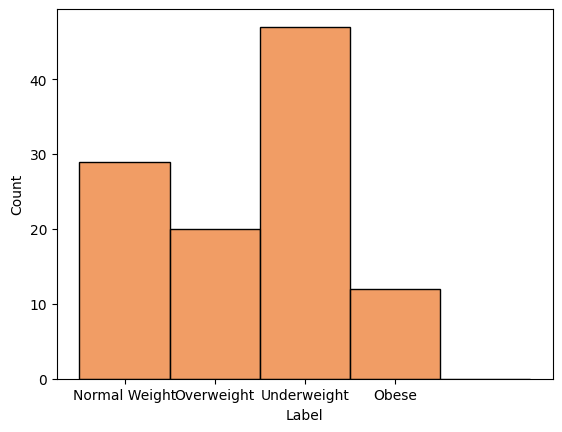

In [12]:
histo1 = sns.histplot(df, x='Label', color='#ED7D31',  binrange=(0,4), binwidth=1)

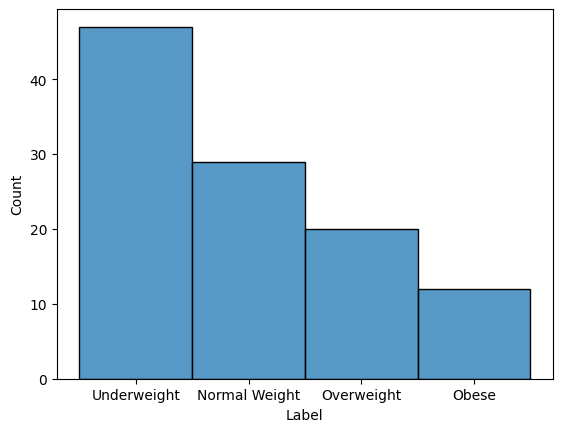

In [13]:
df['Label'] = pd.Categorical(df['Label'], ['Underweight', 'Normal Weight', 'Overweight', 'Obese'])
histo2 = sns.histplot(df, x='Label')

In [14]:
df_mod = df.replace({'Label': { 'Normal Weight':1, 'Overweight':2, 'Underweight':0, 'Obese':3 }})
df_mod

/tmp/ipython-input-445688769.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_mod = df.replace({'Label': { 'Normal Weight':1, 'Overweight':2, 'Underweight':0, 'Obese':3 }})
/tmp/ipython-input-445688769.py:1: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  df_mod = df.replace({'Label': { 'Normal Weight':1, 'Overweight':2, 'Underweight':0, 'Obese':3 }})


,Age,Gender,Height,Weight,BMI,Label
ID,,,,,,
1,25,Male,175,80,25.3,1
2,30,Female,160,60,22.5,1
3,35,Male,180,90,27.3,2
4,40,Female,150,50,20.0,0
5,45,Male,190,100,31.2,3
...,...,...,...,...,...,...
106,11,Male,175,10,3.9,0
107,16,Female,160,10,3.9,0
108,21,Male,180,15,5.6,0


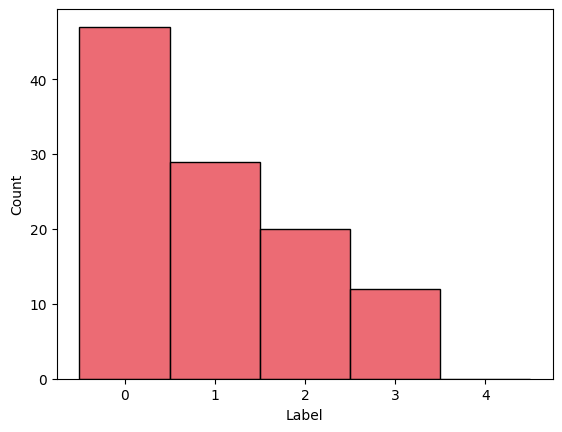

In [15]:
histo3 = sns.histplot(df_mod, x='Label', color='#e63946',  binrange=(0,4), binwidth=1)

## Histogramas con filtros

Crearemos un histograma para la clase de *Obese*.

Filtramos los datos.

In [16]:
obeso = df.loc[(df['Label'] == 'Obese')]
obeso

,Age,Gender,Height,Weight,BMI,Label
ID,,,,,,
5,45,Male,190,100,31.2,Obese
7,55,Male,200,110,34.2,Obese
9,65,Male,210,120,37.2,Obese
17,48,Male,200,100,31.2,Obese
20,58,Male,210,110,34.2,Obese
26,88,Male,190,100,31.2,Obese
28,98,Male,200,110,34.2,Obese
30,108,Male,210,120,37.2,Obese
37,49,Male,200,105,28.9,Obese


Creamos el histograma.

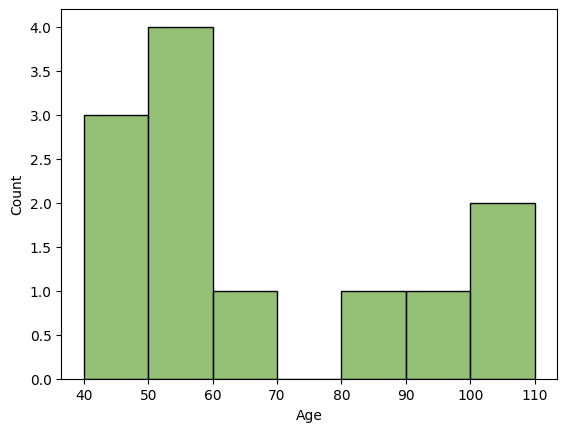

In [17]:
edad_obeso = sns.histplot(obeso, x='Age', color='#70AD47', binrange=(40,110), binwidth=10)

Creamos un histograma para la clase *Underweight* separado por género.

Filtramos los datos.

In [18]:
under = df.loc[(df['Label'] == 'Underweight')]
under.head()

,Age,Gender,Height,Weight,BMI,Label
ID,,,,,,
4,40,Female,150,50,20.0,Underweight
6,50,Female,140,40,16.7,Underweight
8,60,Female,130,30,13.3,Underweight
10,70,Female,120,20,10.0,Underweight
12,23,Female,160,50,20.0,Underweight


Crear el histograma.

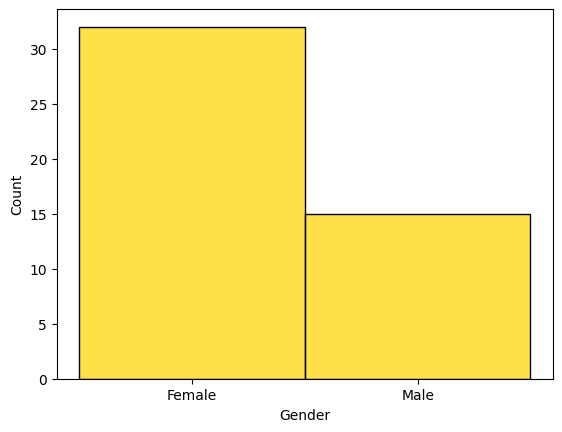

In [19]:
comp_under = sns.histplot(data=under, x='Gender', color='#ffd60a')
plt.show()

#**Gráfica circular**

Crear una gráfica circular para las clases de la columna *Label*.

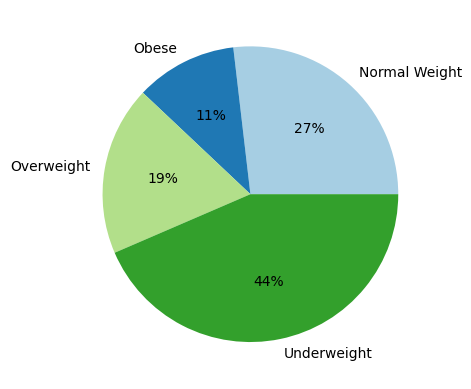

In [20]:
# Escogemos los colores que queremos utilizar
palette_color = sns.color_palette('Paired')

# Crear la gráfica con plt.pie
plt.pie(tab.frecuencia, labels=tab.Label, colors=palette_color, autopct='%.0f%%')

# Mostrar la gráfica
plt.show()

#**Polígono de frecuencias**

Crear un polígono de frecuencias para las clases de la columna Label.

<Axes: xlabel='Label', ylabel='frecuencia'>

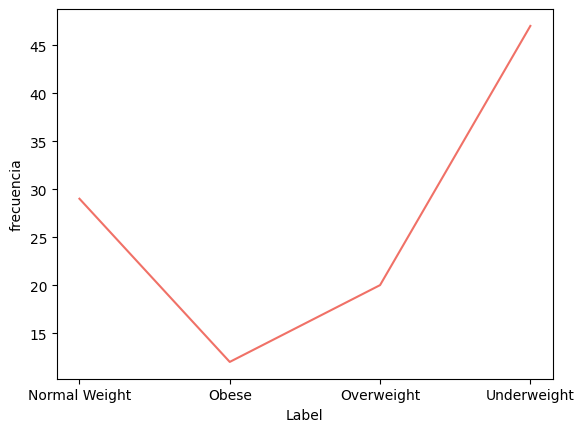

In [21]:
sns.lineplot(data=tab, x="Label", y="frecuencia", markers=True, color='#f07167')

#**Diagrama de dispersión**

Hacer un diagrama de dispersión para ver si existe una correlación entre el peso y la edad.

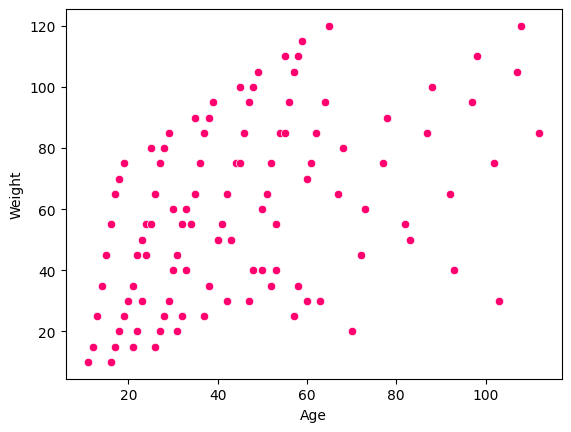

In [22]:
dispersion = sns.scatterplot(df, x='Age', y='Weight', color='#ff006e')